# Day 40 | Ask a Small Database in Plain English

**KGP Talkie**

Follow schema, SQL, validation, execution, and result steps.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

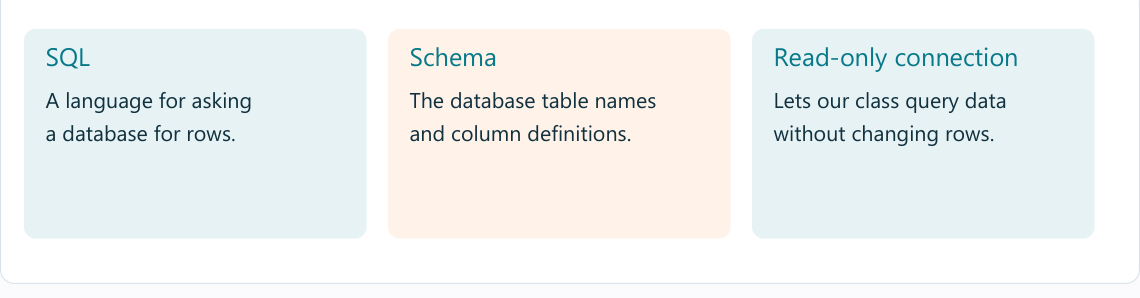

SQLite gives us a local database without a server account. re checks the simple query form used here.

In [4]:
import sqlite3
import re

In [5]:
database = OUTPUT / "students.db"
setup = sqlite3.connect(database)

In [6]:
setup.execute("CREATE TABLE IF NOT EXISTS students (name TEXT, score INTEGER)")

Only this small classroom fixture is written during setup. ? parameters keep data separate from SQL syntax.

In [7]:
setup.execute("DELETE FROM students")
setup.executemany("INSERT INTO students VALUES (?, ?)", [("Asha", 82), ("Ravi", 70), ("Mia", 91)])

In [8]:
setup.commit()
setup.close()

mode=ro makes this query connection read-only. A prompt or keyword check alone cannot enforce that boundary.

In [9]:
db = sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)

In [10]:
schema = db.execute("PRAGMA table_info(students)").fetchall()
print(schema)

[(0, 'name', 'TEXT', 0, None, 0), (1, 'score', 'INTEGER', 0, None, 0)]


The database authorizer allows SELECT, reads of students, and a short list of aggregate functions. Everything else is denied.

In [11]:
def authorize(action, table, column, database_name, trigger):
    if action == sqlite3.SQLITE_SELECT:
        return sqlite3.SQLITE_OK
    if action == sqlite3.SQLITE_READ and table == "students":
        return sqlite3.SQLITE_OK
    if action == sqlite3.SQLITE_FUNCTION and column.lower() in {"max", "min", "avg", "sum", "count"}:
        return sqlite3.SQLITE_OK
    return sqlite3.SQLITE_DENY

In [12]:
db.set_authorizer(authorize)

closing makes sure a database connection is closed after the block, even if a query fails.

In [13]:
from contextlib import closing

Each call opens its own read-only connection because an agent may run tools in another thread. The authorizer is applied to every new connection. At most ten rows are returned.

In [14]:
def query_rows(query):
    clean = query.strip().removeprefix("```sql").removesuffix("```").strip().rstrip(";")
    if not re.match(r"^SELECT\b", clean, re.IGNORECASE) or ";" in clean:
        raise ValueError("Use one SELECT query only.")
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as query_db:
        query_db.set_authorizer(authorize)
        return query_db.execute(clean).fetchmany(10)

In [15]:
query_rows("SELECT name, score FROM students ORDER BY score DESC LIMIT 1")

[('Mia', 91)]

Show one denied action. No update is sent to the database.

In [16]:
try:
    query_rows("UPDATE students SET score = 0")
except ValueError as error:
    print("Rejected:", error)

Rejected: Use one SELECT query only.


ChatOllama sends chat requests to the local Ollama server.

In [17]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [18]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [19]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [20]:
sql = llm.invoke(f"Return only one SQLite SELECT, no Markdown. Table students has name TEXT and score INTEGER. Question: Who has the highest score?").content
print(sql)

SELECT name FROM students ORDER BY score DESC LIMIT 1


Inspect the model's query before running. The connection and authorizer enforce the permissions.

In [21]:
print(query_rows(sql))

[('Mia',)]


In [22]:
from langchain_core.tools import tool
from langchain.agents import create_agent

In [23]:
@tool
def read_schema() -> str:
    """Return the only allowed table schema: students(name TEXT, score INTEGER)."""
    return "students(name TEXT, score INTEGER)"

@tool
def run_select(query: str) -> str:
    """Run one read-only SQLite SELECT on students; return at most ten rows."""
    return str(query_rows(query))

In [24]:
agent = create_agent(llm, [read_schema, run_select], system_prompt="Read the schema first. Use a SELECT tool to answer from rows. Do not change data. Keep the final answer short.")

In [25]:
fresh = agent.invoke({"messages": [{"role": "user", "content": "What is the average score?"}]}, config={"recursion_limit": 12})

In [26]:
[(m.type, m.content, getattr(m, "tool_calls", [])) for m in fresh["messages"]]

[('human', 'What is the average score?', []),
 ('ai',
  '',
  [{'name': 'run_select',
    'args': {'query': 'SELECT AVG(score) FROM students'},
    'id': 'e0b110c4-9f4b-437d-b2a5-b29db0824d1a',
    'type': 'tool_call'}]),
 ('tool', '[(81.0,)]', []),
 ('ai', 'The average score is 81.0.', [])]

In [27]:
db.close()

The course title mentions MySQL. Its supplied agent notebook uses SQLite. A MySQL extension needs a MySQL server, a read-only database user, and connection settings; this notebook uses no live database credentials.

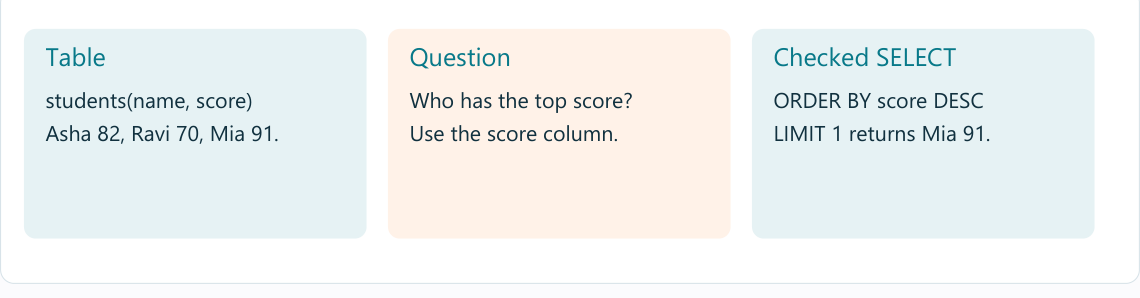

## Try a fresh input

Create an agent with schema and query tools. Try a different score question and inspect its tool result.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-text-to-mysql).